# GCI Global 2026 In-class Competition — Home Credit Default Risk

This notebook predicts the probability that a client defaults on a loan (`TARGET = 1`) and writes `output/submission.csv` for Omnicampus. The metric is ROC-AUC.

## Approach
1. **Data cleaning** — placeholder values (`DAYS_EMPLOYED = 365243`, `OWN_CAR_AGE` ≥ 60, `XNA` / `Unknown` labels, one impossible enquiry count) are replaced with `NaN`. No rows are removed and missing values are not imputed.
2. **Feature engineering** — two ratio features are added: `CREDIT_TERM` and `CREDIT_TO_GOODS`. Text columns are converted to integer codes.
3. **Validation** — stratified 80/20 train/validation split. Hyperparameters are tuned with 3-fold cross-validation inside the training part only, so the validation part stays untouched until the final check.
4. **Models** — six baseline models are compared. LightGBM and CatBoost are tuned with Optuna and their predicted probabilities are averaged.

## Result (recorded run)
| Model | Validation ROC-AUC |
|---|---|
| LightGBM (tuned) | 0.7606 |
| CatBoost (tuned) | 0.7592 |
| Average of both | **0.7610** |

## Reproducibility
- Random seed fixed (`SEED = 42`).
- Only the provided `train.csv` and `test.csv` are used. No external data and no manual predictions.
- The hyperparameter search takes about 25 minutes, so the best settings it found are stored in the notebook. Set `RUN_SEARCH = True` to repeat the search.
- How to run: set `DATA_DIR` in the Setup cell, then Run All.

# 1. Setup

In [1]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

SEED = 42
RUN_SEARCH = False   # True = repeat the Optuna hyperparameter search (about 25 minutes)

# Folder that contains train.csv and test.csv
DATA_DIR = Path(r"C:\Users\Ibro\Downloads\Telegram Desktop")
if (Path("input") / "train.csv").exists():      # competition folder layout
    DATA_DIR = Path("input")
OUT_DIR = DATA_DIR / "output"

In [2]:
# Libraries that are not part of a standard Python installation
# %pip install lightgbm xgboost catboost optuna

In [3]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print(train.shape, test.shape)

(171202, 34) (61500, 33)


# 2. Data overview

In [4]:
df = train.copy()   # a separate copy used only for exploration

print('<Dataset Shape>')
print(f"Total number of Rows: {df.shape[0]}")
print(f"Total number of Columns: {df.shape[1]}")

<Dataset Shape>
Total number of Rows: 171202
Total number of Columns: 34


In [5]:
df.sample(7, random_state=SEED)

,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,...,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
163347,163347,Cash loans,F,2,135000.0,675000.0,20596.5,675000.0,Working,Higher education,...,Industry: type 9,0.435635,0.717522,0.529890,-1170.0,0.0,0.0,1.0,2.0,0
50001,50001,Cash loans,M,3,247500.0,526500.0,19642.5,526500.0,Working,Secondary / secondary special,...,Business Entity Type 3,NaN,0.135969,0.656158,-2.0,0.0,0.0,0.0,0.0,0
84327,84327,Cash loans,F,0,90000.0,942300.0,30528.0,675000.0,Working,Secondary / secondary special,...,Trade: type 3,NaN,0.764047,0.355639,-1635.0,0.0,0.0,0.0,1.0,0
141409,141409,Cash loans,F,0,135000.0,358443.0,13639.5,252000.0,Working,Secondary / secondary special,...,Self-employed,NaN,0.502823,NaN,-1511.0,0.0,0.0,0.0,5.0,0
56140,56140,Cash loans,F,0,157500.0,312768.0,16506.0,270000.0,Commercial associate,Secondary / secondary special,...,Business Entity Type 2,NaN,0.668752,0.374021,-645.0,0.0,1.0,0.0,2.0,0
57425,57425,Cash loans,F,0,99000.0,301464.0,8766.0,238500.0,State servant,Secondary / secondary special,...,Government,NaN,0.546641,0.244516,-3.0,0.0,0.0,0.0,0.0,1
35103,35103,Cash loans,F,3,270000.0,1214100.0,66663.0,1125000.0,Working,Higher education,...,Business Entity Type 3,NaN,0.666768,0.551381,-478.0,0.0,0.0,1.0,0.0,0


In [6]:
print('<Data Types>')
df.info()

<Data Types>
<class 'pandas.DataFrame'>
RangeIndex: 171202 entries, 0 to 171201
Data columns (total 34 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   SK_ID_CURR                  171202 non-null  int64  
 1   NAME_CONTRACT_TYPE          171202 non-null  str    
 2   CODE_GENDER                 171202 non-null  str    
 3   CNT_CHILDREN                171202 non-null  int64  
 4   AMT_INCOME_TOTAL            171202 non-null  float64
 5   AMT_CREDIT                  171202 non-null  float64
 6   AMT_ANNUITY                 171202 non-null  float64
 7   AMT_GOODS_PRICE             171202 non-null  float64
 8   NAME_INCOME_TYPE            171202 non-null  str    
 9   NAME_EDUCATION_TYPE         171202 non-null  str    
 10  NAME_FAMILY_STATUS          171202 non-null  str    
 11  NAME_HOUSING_TYPE           171202 non-null  str    
 12  REGION_POPULATION_RELATIVE  171202 non-null  float64
 13  DAYS_BIRTH  

In [7]:
print(f"Missing Values: {df.isnull().sum().sum()}")
print(f"Duplicates: {df.duplicated().sum()}")

df.isnull().sum()

Missing Values: 379341
Duplicates: 0


SK_ID_CURR                         0
NAME_CONTRACT_TYPE                 0
CODE_GENDER                        0
CNT_CHILDREN                       0
AMT_INCOME_TOTAL                   0
AMT_CREDIT                         0
AMT_ANNUITY                        0
AMT_GOODS_PRICE                    0
NAME_INCOME_TYPE                   0
NAME_EDUCATION_TYPE                0
NAME_FAMILY_STATUS                 0
NAME_HOUSING_TYPE                  0
REGION_POPULATION_RELATIVE         0
DAYS_BIRTH                         0
DAYS_EMPLOYED                      0
DAYS_REGISTRATION                  0
DAYS_ID_PUBLISH                    0
OWN_CAR_AGE                   112992
FLAG_MOBIL                         0
FLAG_EMP_PHONE                     0
FLAG_WORK_PHONE                    0
OCCUPATION_TYPE                    0
CNT_FAM_MEMBERS                    2
REGION_RATING_CLIENT               0
ORGANIZATION_TYPE                  0
EXT_SOURCE_1                  118928
EXT_SOURCE_2                     369
E

In [8]:
df.describe()

,SK_ID_CURR,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,...,REGION_RATING_CLIENT,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,DAYS_LAST_PHONE_CHANGE,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,TARGET
count,171202.00000,171202.000000,1.712020e+05,1.712020e+05,171202.000000,1.712020e+05,171202.000000,171202.000000,171202.000000,171202.000000,...,171202.000000,52274.000000,1.708330e+05,116616.000000,171202.000000,148086.000000,148086.000000,148086.000000,148086.000000,171202.000000
mean,85600.50000,0.416490,1.683712e+05,5.991293e+05,27120.065953,5.380569e+05,0.020839,-16045.340504,63960.411969,-4994.982524,...,2.053726,0.501692,5.145083e-01,0.511177,-962.407773,0.006652,0.268418,0.267547,1.903644,0.080729
std,49421.90473,0.720138,1.072348e+05,4.028170e+05,14450.252689,3.685727e+05,0.013803,4363.792228,141401.513149,3525.760241,...,0.508718,0.210950,1.912729e-01,0.194778,826.277244,0.086204,0.921022,0.914532,1.872237,0.272420
min,0.00000,0.000000,2.610000e+04,4.500000e+04,1980.000000,4.500000e+04,0.000290,-25229.000000,-17912.000000,-24672.000000,...,1.000000,0.017095,8.173617e-08,0.000527,-4173.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,42800.25000,0.000000,1.125000e+05,2.700000e+05,16546.500000,2.385000e+05,0.010006,-19686.000000,-2772.000000,-7490.000000,...,2.000000,0.333353,3.920925e-01,0.370650,-1568.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,85600.50000,0.000000,1.462500e+05,5.146020e+05,24916.500000,4.500000e+05,0.018850,-15778.000000,-1215.000000,-4515.000000,...,2.000000,0.505858,5.662998e-01,0.537070,-757.000000,0.000000,0.000000,0.000000,1.000000,0.000000
75%,128400.75000,1.000000,2.025000e+05,8.086500e+05,34600.500000,6.795000e+05,0.028663,-12420.000000,-288.000000,-2008.000000,...,2.000000,0.674595,6.641587e-01,0.669057,-274.000000,0.000000,0.000000,0.000000,3.000000,0.000000
max,171201.00000,14.000000,1.350000e+07,4.050000e+06,170986.500000,2.254500e+06,0.072508,-7673.000000,365243.000000,0.000000,...,3.000000,0.947649,8.549997e-01,0.896010,0.000000,4.000000,23.000000,261.000000,23.000000,1.000000


## Dataset Overview

The training data has **171,202 rows and 34 columns**: 1 ID column (`SK_ID_CURR`), 32 features and the target (`TARGET`). There are no duplicate rows.

- **Data types:** 26 numeric columns and 8 text columns (e.g. `NAME_CONTRACT_TYPE`, `CODE_GENDER`, `OCCUPATION_TYPE`, `ORGANIZATION_TYPE`).
- **Target:** only **8.07%** of clients defaulted (`TARGET = 1`), so the dataset is **highly imbalanced**. This is why ROC-AUC is used instead of accuracy.
- **Missing values (379,341 in total):**
  - `EXT_SOURCE_1` (~69%), `OWN_CAR_AGE` (~66%) and `EXT_SOURCE_3` (~32%) are missing a lot.
  - The four `AMT_REQ_CREDIT_BUREAU_*` columns are each missing 23,116 values (~13.5%).
  - `EXT_SOURCE_2` and `CNT_FAM_MEMBERS` are missing only a few values.
- **Anomalies found:**
  - `DAYS_EMPLOYED` has a maximum of **365,243** (about 1,000 years), which is a placeholder, not a real number of days.
  - `AMT_INCOME_TOTAL` has a maximum of 13.5M while the median is 146K.
  - `AMT_REQ_CREDIT_BUREAU_QRT` has a maximum of 261 while its 75th percentile is 0.
- **`DAYS_*` columns are negative** because they count days *before* the application (e.g. `DAYS_BIRTH = -16045` ≈ 44 years old).

# 3. Exploratory data analysis

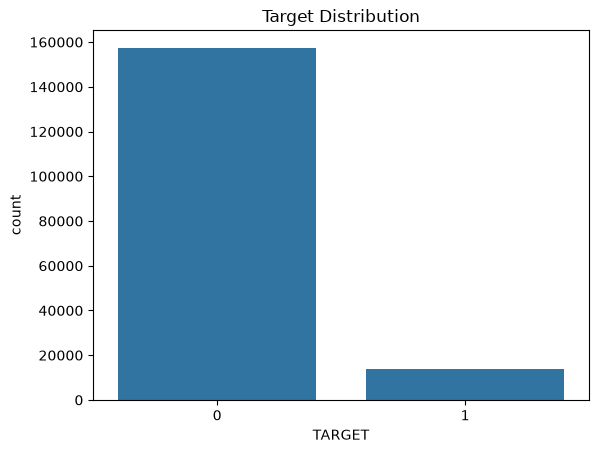

In [9]:
sns.countplot(df, x='TARGET')
plt.title('Target Distribution')
plt.show()

The target is highly imbalanced: about 92% of clients did not default. Accuracy would be misleading here (predicting "no default" for everyone scores 92%), which is why ROC-AUC is the metric.

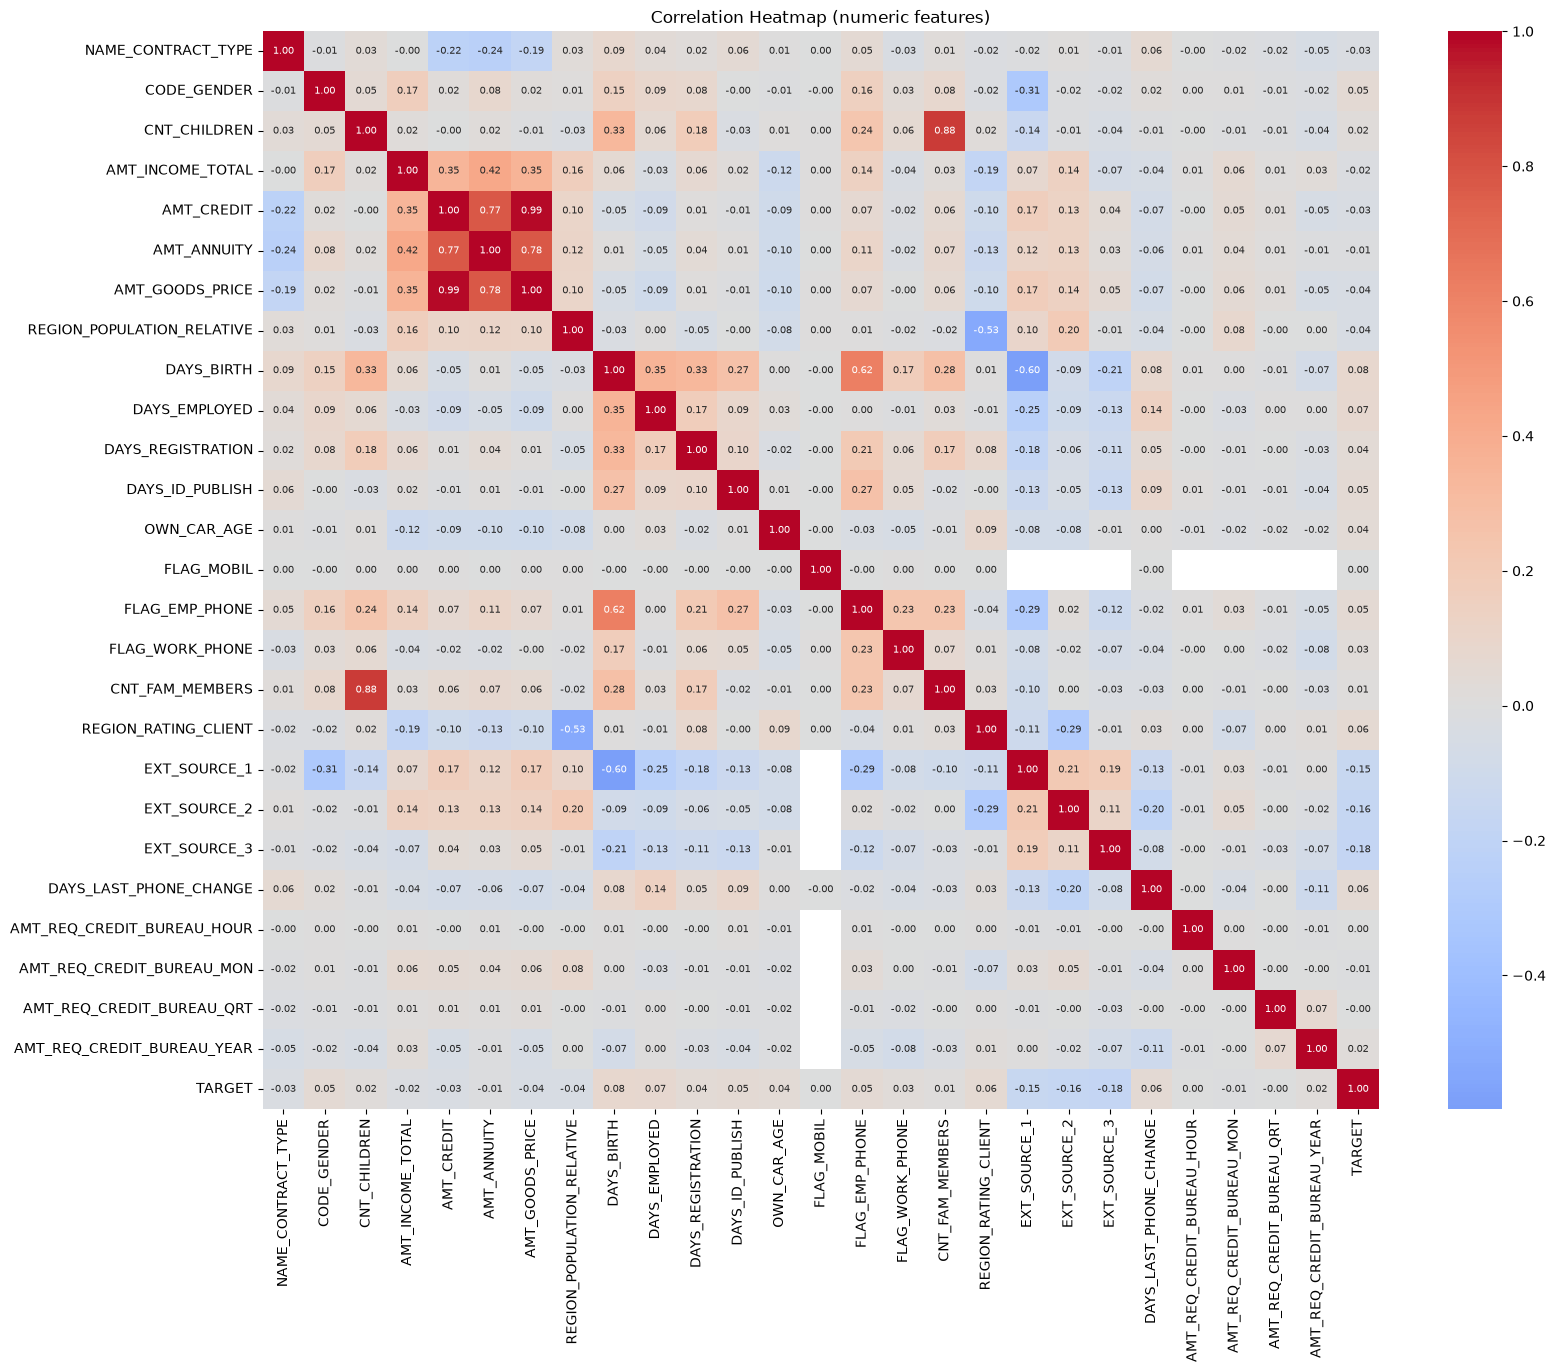

EXT_SOURCE_3             -0.178317
EXT_SOURCE_2             -0.162562
EXT_SOURCE_1             -0.154050
DAYS_BIRTH                0.079541
DAYS_EMPLOYED             0.073608
REGION_RATING_CLIENT      0.058984
DAYS_LAST_PHONE_CHANGE    0.055194
CODE_GENDER               0.054457
DAYS_ID_PUBLISH           0.052567
FLAG_EMP_PHONE            0.045646
Name: TARGET, dtype: float64


In [10]:
# The changes in this cell are made on the exploration copy only
df["DAYS_EMPLOYED"] = df["DAYS_EMPLOYED"].replace(365243, np.nan)
df["NAME_CONTRACT_TYPE"] = (df["NAME_CONTRACT_TYPE"] == "Revolving loans").astype(int)
df["CODE_GENDER"] = (df["CODE_GENDER"] == "M").astype(int)

num = df.select_dtypes(include="number").drop(columns=["SK_ID_CURR"])
num = num.loc[:, num.std() > 0]

plt.figure(figsize=(18, 14))
sns.heatmap(num.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7})
plt.title("Correlation Heatmap (numeric features)")
plt.show()

# Which features correlate most with TARGET
print(num.corr()["TARGET"].drop("TARGET").sort_values(key=abs, ascending=False).head(10))

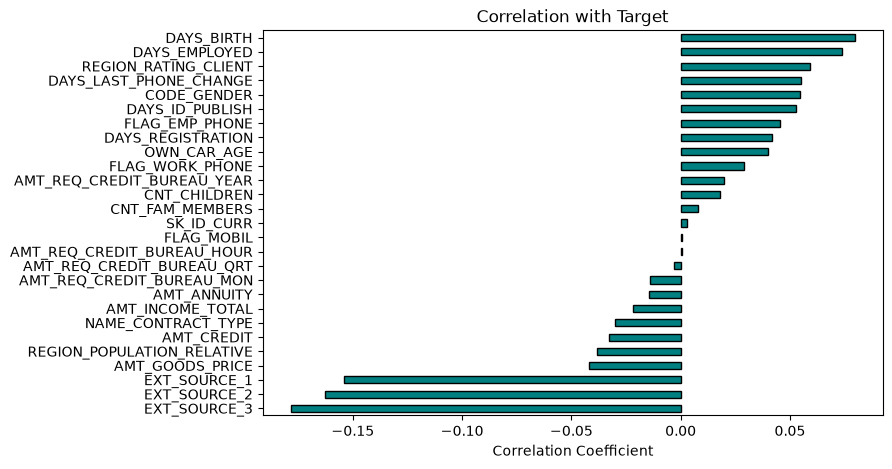

In [11]:
num_cols = df.select_dtypes(include='number')

target_corr = num_cols.corr()['TARGET'].sort_values(ascending=True)

plt.figure(figsize=(8, 5))
target_corr.drop('TARGET').plot(kind='barh', color='teal', edgecolor='black')
plt.title("Correlation with Target")
plt.xlabel("Correlation Coefficient")
plt.show()

The three external scores (`EXT_SOURCE_1/2/3`) have by far the strongest relationship with default. All correlations are weak in absolute terms (below 0.2), which signals that no single column predicts default well and that a non-linear model is needed.

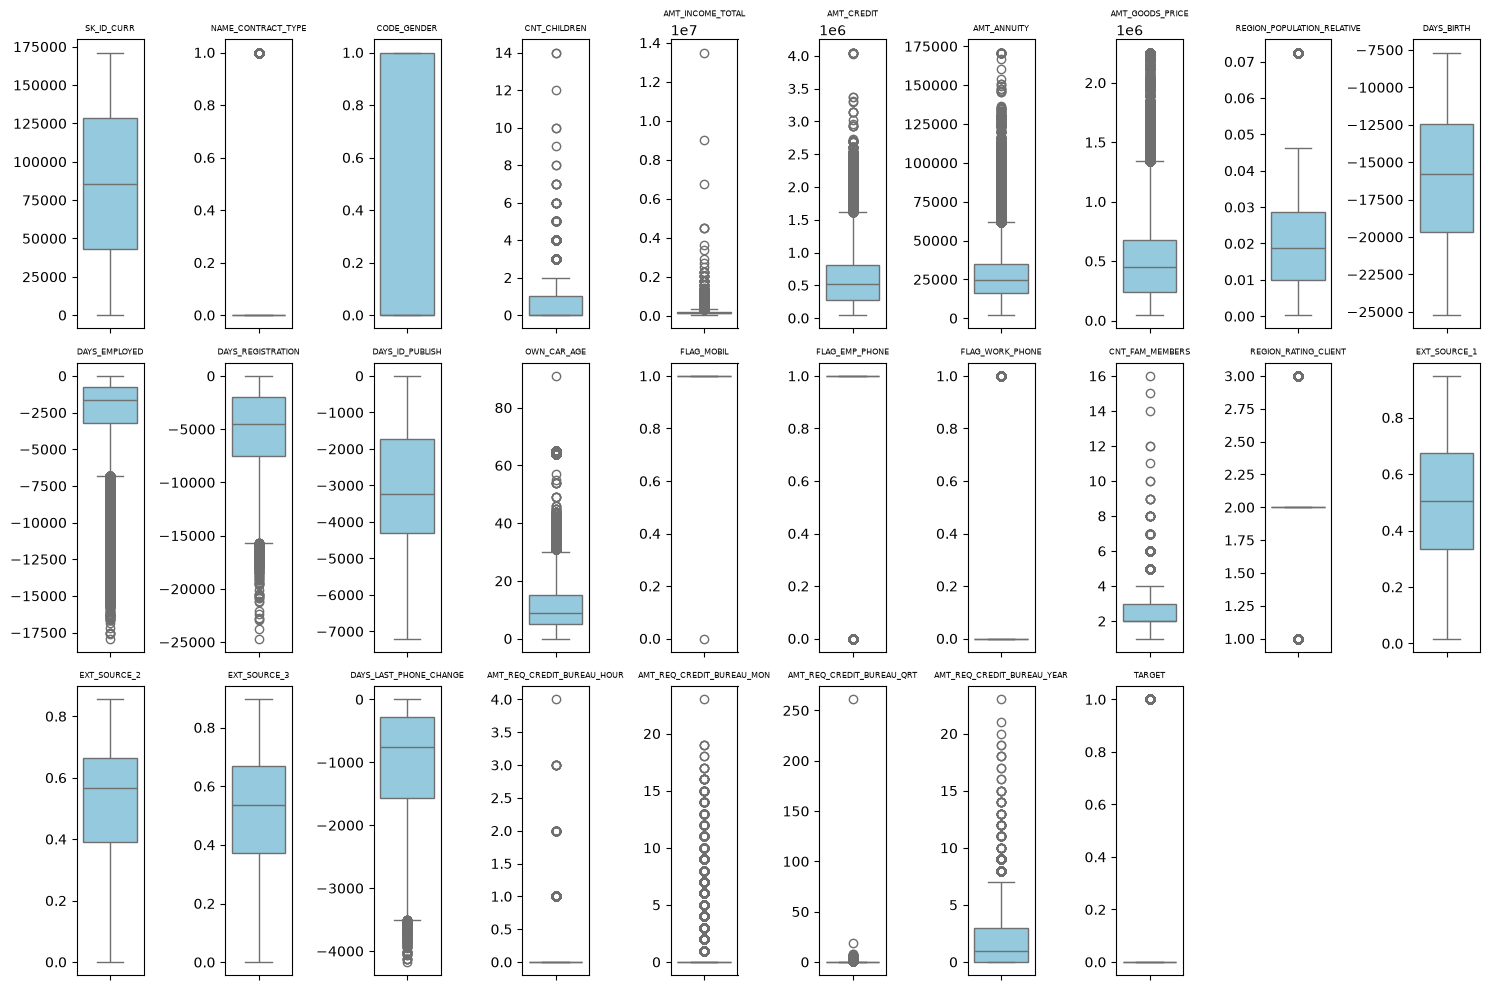

In [12]:
plt.figure(figsize=(15, 10))

for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 10, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(col, fontsize=6)
    plt.ylabel('')

plt.tight_layout()
plt.show()

In [13]:
print("--- SKEWNESS (numeric features) ---")
for c in num_cols:
    print(f"{c:28s} skew: {df[c].skew():8.3f}")

--- SKEWNESS (numeric features) ---
SK_ID_CURR                   skew:    0.000
NAME_CONTRACT_TYPE           skew:    2.768
CODE_GENDER                  skew:    0.663
CNT_CHILDREN                 skew:    1.887
AMT_INCOME_TOTAL             skew:   20.118
AMT_CREDIT                   skew:    1.238
AMT_ANNUITY                  skew:    1.441
AMT_GOODS_PRICE              skew:    1.310
REGION_POPULATION_RELATIVE   skew:    1.485
DAYS_BIRTH                   skew:   -0.111
DAYS_EMPLOYED                skew:   -1.956
DAYS_REGISTRATION            skew:   -0.588
DAYS_ID_PUBLISH              skew:    0.346
OWN_CAR_AGE                  skew:    2.741
FLAG_MOBIL                   skew: -413.766
FLAG_EMP_PHONE               skew:   -1.661
FLAG_WORK_PHONE              skew:    1.502
CNT_FAM_MEMBERS              skew:    0.944
REGION_RATING_CLIENT         skew:    0.090
EXT_SOURCE_1                 skew:   -0.071
EXT_SOURCE_2                 skew:   -0.792
EXT_SOURCE_3                 skew:   -0.

Several columns are strongly right-skewed (`AMT_INCOME_TOTAL`, the bureau enquiry counts). The boxplots mark many points as outliers, but for binary flags and count columns the boxplot rule is not meaningful, and the large incomes and loans are real clients. See "Deliberate non-actions" below.

# 4. Data cleaning

**Approach:** fix values that are wrong, keep values that are only unusual.
- Placeholder codes (such as `365243` days) are replaced with `NaN`.
- No rows are deleted: extreme incomes and loans are real clients, and the test set contains them too.
- Missing values are not filled: gradient-boosting models handle `NaN` natively, and missingness itself predicts default.
- Every step is a fixed row-wise rule applied identically to train and test. No step uses `TARGET` or any statistic from the test set, so there is no data leakage.

### Step 1 — `DAYS_EMPLOYED`: remove the placeholder value
`DAYS_EMPLOYED` should be negative (days before the application). 30,898 training rows contain exactly `365243` (about 1,000 years). These are all pensioners or unemployed clients, so the value is a code for "not employed", not a number.

**Action:** replace `365243` with `NaN`.
**Why:** the fake value would distort the column. No extra flag is needed: the model reads `NaN` directly, and `FLAG_EMP_PHONE` already identifies this group.

In [14]:
for d in [train, test]:
    d["DAYS_EMPLOYED"] = d["DAYS_EMPLOYED"].where(d["DAYS_EMPLOYED"] != 365243, np.nan)

print("missing in train:", train["DAYS_EMPLOYED"].isna().sum())
print("missing in test: ", test["DAYS_EMPLOYED"].isna().sum())
print("max now:", train["DAYS_EMPLOYED"].max())

missing in train: 30898
missing in test:  10565
max now: -1.0


### Step 2 — Placeholder categories
`CODE_GENDER` has 4 rows labelled `XNA` and `NAME_FAMILY_STATUS` has 2 rows labelled `Unknown`. They appear only in train, never in test.

**Action:** replace both with `NaN`.
**Why:** a category with a handful of rows that never appears in test can only be memorised, not learned.

In [15]:
for d in [train, test]:
    d["CODE_GENDER"] = d["CODE_GENDER"].replace("XNA", np.nan)
    d["NAME_FAMILY_STATUS"] = d["NAME_FAMILY_STATUS"].replace("Unknown", np.nan)

print(train["CODE_GENDER"].value_counts(dropna=False))
print(train["NAME_FAMILY_STATUS"].value_counts(dropna=False))

CODE_GENDER
F      112549
M       58649
NaN         4
Name: count, dtype: int64
NAME_FAMILY_STATUS
Married                 109323
Single / not married     25285
Civil marriage           16652
Separated                10988
Widow                     8952
NaN                          2
Name: count, dtype: int64


### Step 3 — `OWN_CAR_AGE`: placeholder ages
Car ages fade out naturally towards 45–57 years, then 1,825 rows sit at exactly 64 or 65 (plus one at 91). This spike is a placeholder for "age unknown", not real cars.

**Action:** set ages ≥ 60 to `NaN`.
**Why:** a placeholder is not a measurement, and leaving it in would tell the model these cars are very old.

In [16]:
print(train["OWN_CAR_AGE"].value_counts().sort_index().tail(8))

for d in [train, test]:
    d["OWN_CAR_AGE"] = d["OWN_CAR_AGE"].where(d["OWN_CAR_AGE"] < 60, np.nan)

print("max now:", train["OWN_CAR_AGE"].max())
print("missing in train:", train["OWN_CAR_AGE"].isna().sum())

OWN_CAR_AGE
46.0       3
49.0       4
54.0       5
55.0       1
57.0       1
64.0    1331
65.0     494
91.0       1
Name: count, dtype: int64
max now: 57.0
missing in train: 114818


### Step 4 — `AMT_REQ_CREDIT_BUREAU_QRT`: impossible value
One training row reports 261 credit-bureau enquiries in a single quarter. The next largest value is 19, and the largest in test is 8.

**Action:** set that value to `NaN`.
**Why:** it is a data-entry error. Other large but plausible values are left unchanged.

In [17]:
col = "AMT_REQ_CREDIT_BUREAU_QRT"
for d in [train, test]:
    d[col] = d[col].where(d[col] <= 50, np.nan)

print("max in train now:", train[col].max())
print("max in test now: ", test[col].max())
print("missing in train:", train[col].isna().sum())

max in train now: 19.0
max in test now:  8.0
missing in train: 23117


### Step 5 — Missing values are kept as they are
The remaining missing values (`EXT_SOURCE_*`, the credit-bureau columns, `OWN_CAR_AGE`, `DAYS_EMPLOYED`) are not filled.

**Why:** missingness carries information, as the table below shows. Filling with a mean or median would make these clients look average. LightGBM and CatBoost handle `NaN` natively, so no imputation is required.

In [18]:
rows = []
for c in ["AMT_REQ_CREDIT_BUREAU_YEAR", "EXT_SOURCE_1", "EXT_SOURCE_3", "OWN_CAR_AGE"]:
    g = train.groupby(train[c].isna())["TARGET"].mean()
    rows.append({"column": c, "default rate if present": g[False], "default rate if missing": g[True]})
pd.DataFrame(rows).round(4)

,column,default rate if present,default rate if missing
0,AMT_REQ_CREDIT_BUREAU_YEAR,0.0771,0.1038
1,EXT_SOURCE_1,0.0749,0.0833
2,EXT_SOURCE_3,0.0771,0.0886
3,OWN_CAR_AGE,0.0720,0.0850


### Step 6 — Drop uninformative columns
- `FLAG_MOBIL` is 1 for every row except one, so it carries no information.
- `CNT_FAM_MEMBERS` always equals `CNT_CHILDREN` + 1 (single) or + 2 (couple), so it duplicates columns we already have.

**Action:** drop both columns.

In [19]:
drop_cols = ["FLAG_MOBIL", "CNT_FAM_MEMBERS"]
train = train.drop(columns=drop_cols)
test = test.drop(columns=drop_cols)

print(train.shape, test.shape)

(171202, 32) (61500, 31)


### Step 7 — Encode the text columns
Eight columns contain text. They are converted to integer codes. The list of categories is taken from the training set only and then applied to the test set, and no category in test is missing from train.

**Why integer codes:** `ORGANIZATION_TYPE` has 58 categories. Letting the model group categories freely leads to memorising small groups (overfitting). One-hot encoding would add 100+ sparse columns. Integer codes are compact and generalise better.

In [20]:
cat_cols = ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
            "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE", "ORGANIZATION_TYPE"]

for c in cat_cols:
    levels = sorted(train[c].dropna().unique())          # categories come from train only
    train[c] = pd.Categorical(train[c], categories=levels).codes
    test[c] = pd.Categorical(test[c], categories=levels).codes
    train[c] = train[c].astype(float).replace(-1, np.nan)  # -1 marks a missing value
    test[c] = test[c].astype(float).replace(-1, np.nan)

print("categories per column:", {c: int(train[c].nunique()) for c in cat_cols})
print("missing codes in test:", int(test[cat_cols].isna().sum().sum()))

categories per column: {'NAME_CONTRACT_TYPE': 2, 'CODE_GENDER': 2, 'NAME_INCOME_TYPE': 8, 'NAME_EDUCATION_TYPE': 5, 'NAME_FAMILY_STATUS': 5, 'NAME_HOUSING_TYPE': 6, 'OCCUPATION_TYPE': 19, 'ORGANIZATION_TYPE': 58}
missing codes in test: 0


### Step 8 — Separate target and ID
`TARGET` is the answer and `SK_ID_CURR` is only a row identifier (train IDs are 0–171,201, test IDs continue after). Neither may be used as a feature.

**Action:** store `TARGET` in `y`, keep the test IDs for the submission, and drop both from the features.

In [21]:
y = train["TARGET"].values
test_ids = test["SK_ID_CURR"].values

X = train.drop(columns=["TARGET", "SK_ID_CURR"])
X_test = test.drop(columns=["SK_ID_CURR"])

print(X.shape, X_test.shape, y.shape)
print("same columns in both:", list(X.columns) == list(X_test.columns))
print("default rate:", y.mean().round(4))

(171202, 30) (61500, 30) (171202,)
same columns in both: True
default rate: 0.0807


### Deliberate non-actions
- **No outlier removal:** the IQR rule would delete about 9% of the training rows. They are ordinary high earners with large loans, and the test set contains the same kind of client.
- **No imputation:** see Step 5.
- **No resampling (SMOTE / undersampling):** only 8% of clients default, but the metric is ROC-AUC, which measures ranking and does not depend on the class ratio. Stratified splitting is used instead.

# 5. Feature engineering

Raw amounts show how large a loan is, but risk depends on how the amounts relate to each other. Tree models cannot easily learn division on their own, so the ratios are created explicitly.

| Feature | Formula | Meaning |
|---|---|---|
| `CREDIT_TERM` | `AMT_CREDIT / AMT_ANNUITY` | Number of payments needed to repay the loan |
| `CREDIT_TO_GOODS` | `AMT_CREDIT / AMT_GOODS_PRICE` | Amount borrowed beyond the price of the goods |

**Leakage check:** each ratio uses only the client's own row. No target and no group statistics are involved.

**Selection:** other candidates were also tried during development (two income ratios and six missing-value flags). They did not improve the cross-validated score and are not included. The importance of the two kept features is measured in Section 9.

In [22]:
for d in [X, X_test]:
    d["CREDIT_TERM"] = d["AMT_CREDIT"] / d["AMT_ANNUITY"]
    d["CREDIT_TO_GOODS"] = d["AMT_CREDIT"] / d["AMT_GOODS_PRICE"]

print(X.shape, X_test.shape)
print(X[["CREDIT_TERM", "CREDIT_TO_GOODS"]].corrwith(pd.Series(y)).round(4))
print()
print("Default rate by fifths of CREDIT_TO_GOODS:")
print(pd.Series(y).groupby(pd.qcut(X["CREDIT_TO_GOODS"], 5, duplicates="drop")).mean().round(4))

(171202, 32) (61500, 32)
CREDIT_TERM       -0.0338
CREDIT_TO_GOODS    0.0689
dtype: float64

Default rate by fifths of CREDIT_TO_GOODS:
CREDIT_TO_GOODS
(0.149, 1.0]      0.0682
(1.0, 1.079]      0.0497
(1.079, 1.145]    0.0674
(1.145, 1.211]    0.0957
(1.211, 6.0]      0.1140
dtype: float64


Clients in the highest fifth of `CREDIT_TO_GOODS` default at about 11.4%, roughly twice the rate of clients who borrow close to the price of the goods. None of the raw columns shows this alone.

In [23]:
# Readiness check before modelling
print("non-numeric columns:", X.select_dtypes(exclude="number").shape[1])
print("infinite values:", int(np.isinf(X).sum().sum()), "|", int(np.isinf(X_test).sum().sum()))
print("constant columns:", [c for c in X.columns if X[c].nunique() <= 1])
print("shapes:", X.shape, X_test.shape, y.shape)

non-numeric columns: 0
infinite values: 0 | 0
constant columns: []
shapes: (171202, 32) (61500, 32) (171202,)


# 6. Train / validation split

The competition test set has no labels, so a validation set is cut out of the training data to score models locally.
- `stratify=y` keeps the 8% default rate identical in both parts.
- `random_state` makes the split reproducible.
- Cleaning and feature engineering were done before the split because every step is a fixed row-wise rule. Steps that learn from data (imputation, scaling) are fitted on the training part only, inside pipelines.

In [24]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import roc_auc_score

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print(f"Train: X={X_train.shape}, y={y_train.shape}")
print(f"Valid: X={X_valid.shape}, y={y_valid.shape}")
print(f"Test : X={X_test.shape}  (competition test set, no labels)")
print(f"Default rate: train={y_train.mean():.4f}, valid={y_valid.mean():.4f}")

Train: X=(136961, 32), y=(136961,)
Valid: X=(34241, 32), y=(34241,)
Test : X=(61500, 32)  (competition test set, no labels)
Default rate: train=0.0807, valid=0.0807


# 7. Baseline models

Six models are trained with ordinary settings and no tuning, and scored on the same validation set. A large gap between the train and validation score means overfitting.

Logistic regression and random forest get median imputation (and scaling for logistic regression) inside a pipeline fitted on `X_train` only.

In [25]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"), StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=SEED)),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(n_estimators=300, min_samples_leaf=50, n_jobs=-1, random_state=SEED)),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=500, learning_rate=0.05, random_state=SEED),
    "LightGBM": LGBMClassifier(n_estimators=500, learning_rate=0.05, random_state=SEED, verbose=-1),
    "XGBoost": XGBClassifier(n_estimators=500, learning_rate=0.05, tree_method="hist", random_state=SEED),
    "CatBoost": CatBoostClassifier(iterations=500, learning_rate=0.05, random_seed=SEED, verbose=0),
}

results = []
for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    train_auc = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
    valid_auc = roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1])
    results.append({"model": name, "train_auc": train_auc, "valid_auc": valid_auc,
                    "gap": train_auc - valid_auc, "seconds": round(time.time() - start)})

baseline = pd.DataFrame(results).sort_values("valid_auc", ascending=False).round(4)
baseline

,model,train_auc,valid_auc,gap,seconds
5,CatBoost,0.7934,0.7571,0.0362,7
4,XGBoost,0.8874,0.7530,0.1344,3
3,LightGBM,0.8884,0.7530,0.1354,2
2,HistGradientBoosting,0.8155,0.7524,0.0631,2
1,Random Forest,0.8655,0.7435,0.1220,18
0,Logistic Regression,0.7349,0.7299,0.0051,1


**Reading the table (recorded run):**
- Gradient boosting is the best family. CatBoost scores highest (0.7571) with the smallest gap.
- LightGBM and XGBoost reach 0.7530 but score about 0.89 on train: they overfit at these settings, so they have the most to gain from tuning.
- Random forest overfits and scores lower (0.7435). Logistic regression has almost no gap but the lowest score (0.7299): it underfits.

**Decision:** tune LightGBM and CatBoost.

### Why LightGBM overfits at default settings
The same model is trained with an increasing number of trees. The train score keeps rising, while the validation score peaks and then falls: every tree after the peak learns noise in the training rows.

In [26]:
for n in [50, 100, 200, 500, 1000]:
    m = LGBMClassifier(n_estimators=n, learning_rate=0.05, random_state=SEED, verbose=-1).fit(X_train, y_train)
    tr = roc_auc_score(y_train, m.predict_proba(X_train)[:, 1])
    va = roc_auc_score(y_valid, m.predict_proba(X_valid)[:, 1])
    print(f"trees={n:5d}  train={tr:.4f}  valid={va:.4f}  gap={tr - va:.4f}")

trees=   50  train=0.7681  valid=0.7418  gap=0.0263
trees=  100  train=0.7932  valid=0.7521  gap=0.0412
trees=  200  train=0.8265  valid=0.7539  gap=0.0725
trees=  500  train=0.8884  valid=0.7530  gap=0.1354
trees= 1000  train=0.9433  valid=0.7509  gap=0.1924


# 8. Hyperparameter tuning

**Method:** Optuna (TPE sampler, fixed seed) searches the settings. Each candidate is scored with 3-fold stratified cross-validation **inside `X_train` only**, with early stopping choosing the number of trees. `X_valid` is never used during the search, so it remains a fair final check.

The search takes about 25 minutes in total, so the best settings found in the recorded run are stored below and used when `RUN_SEARCH = False`.

### 8.1 LightGBM

In [27]:
# Best settings found by the search below (30 trials, best CV AUC 0.7610)
lgb_best = {'objective': 'binary', 'learning_rate': 0.03, 'subsample_freq': 1, 'random_state': SEED,
            'verbose': -1, 'n_estimators': 932, 'num_leaves': 15, 'min_child_samples': 389,
            'subsample': 0.9099540249934811, 'colsample_bytree': 0.43560909309815804,
            'reg_alpha': 0.0019710919935471373, 'reg_lambda': 7.6710437169028864}

if RUN_SEARCH:
    import optuna
    import lightgbm as lgb

    def lgb_objective(trial):
        params = dict(
            objective="binary", metric="auc", n_estimators=3000, learning_rate=0.03,
            num_leaves=trial.suggest_int("num_leaves", 8, 48),
            min_child_samples=trial.suggest_int("min_child_samples", 50, 400),
            subsample=trial.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.3, 1.0),
            reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
            reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
            random_state=SEED, verbose=-1,
        )
        scores, trees = [], []
        skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
        for tr_idx, va_idx in skf.split(X_train, y_train):
            model = LGBMClassifier(**params)
            model.fit(X_train.iloc[tr_idx], y_train[tr_idx],
                      eval_set=[(X_train.iloc[va_idx], y_train[va_idx])],
                      callbacks=[lgb.early_stopping(100, verbose=False)])
            pred = model.predict_proba(X_train.iloc[va_idx])[:, 1]
            scores.append(roc_auc_score(y_train[va_idx], pred))
            trees.append(model.best_iteration_)
        trial.set_user_attr("n_trees", int(np.mean(trees)))
        return np.mean(scores)

    lgb_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    lgb_study.optimize(lgb_objective, n_trials=30)
    lgb_best = dict(objective="binary", learning_rate=0.03, subsample_freq=1, random_state=SEED, verbose=-1,
                    n_estimators=int(lgb_study.best_trial.user_attrs["n_trees"] * 1.1), **lgb_study.best_params)
    print("Best CV AUC inside train:", round(lgb_study.best_value, 4))

# fit on all of X_train, then check on the untouched X_valid
lgb_tuned = LGBMClassifier(**lgb_best).fit(X_train, y_train)
print("Train AUC:", round(roc_auc_score(y_train, lgb_tuned.predict_proba(X_train)[:, 1]), 4))
print("Valid AUC:", round(roc_auc_score(y_valid, lgb_tuned.predict_proba(X_valid)[:, 1]), 4), "(baseline 0.7530)")
print("Settings:", lgb_best)

Train AUC: 0.8106
Valid AUC: 0.7606 (baseline 0.7530)
Settings: {'objective': 'binary', 'learning_rate': 0.03, 'subsample_freq': 1, 'random_state': 42, 'verbose': -1, 'n_estimators': 932, 'num_leaves': 15, 'min_child_samples': 389, 'subsample': 0.9099540249934811, 'colsample_bytree': 0.43560909309815804, 'reg_alpha': 0.0019710919935471373, 'reg_lambda': 7.6710437169028864}


### 8.2 CatBoost

In [28]:
# Best settings found by the search below (20 trials, best CV AUC 0.7592)
cat_best = {'learning_rate': 0.05, 'bootstrap_type': 'Bernoulli', 'random_seed': SEED, 'verbose': 0,
            'iterations': 1777, 'depth': 4, 'l2_leaf_reg': 23.196217198452217,
            'random_strength': 3.3249434493993184, 'subsample': 0.8340658614016189,
            'rsm': 0.43062822880128454}

if RUN_SEARCH:
    def cat_objective(trial):
        params = dict(
            iterations=3000, learning_rate=0.05, eval_metric="AUC",
            depth=trial.suggest_int("depth", 4, 8),
            l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 1.0, 30.0, log=True),
            random_strength=trial.suggest_float("random_strength", 0.5, 5.0),
            bootstrap_type="Bernoulli",
            subsample=trial.suggest_float("subsample", 0.6, 1.0),
            rsm=trial.suggest_float("rsm", 0.3, 1.0),
            random_seed=SEED, verbose=0,
        )
        scores, trees = [], []
        skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
        for tr_idx, va_idx in skf.split(X_train, y_train):
            model = CatBoostClassifier(**params)
            model.fit(X_train.iloc[tr_idx], y_train[tr_idx],
                      eval_set=(X_train.iloc[va_idx], y_train[va_idx]),
                      early_stopping_rounds=100)
            pred = model.predict_proba(X_train.iloc[va_idx])[:, 1]
            scores.append(roc_auc_score(y_train[va_idx], pred))
            trees.append(model.get_best_iteration() + 1)
        trial.set_user_attr("n_trees", int(np.mean(trees)))
        return np.mean(scores)

    cat_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    cat_study.optimize(cat_objective, n_trials=20)
    cat_best = dict(learning_rate=0.05, bootstrap_type="Bernoulli", random_seed=SEED, verbose=0,
                    iterations=int(cat_study.best_trial.user_attrs["n_trees"] * 1.1), **cat_study.best_params)
    print("Best CV AUC inside train:", round(cat_study.best_value, 4))

# fit on all of X_train, then check on the untouched X_valid
cat_tuned = CatBoostClassifier(**cat_best).fit(X_train, y_train)
print("Train AUC:", round(roc_auc_score(y_train, cat_tuned.predict_proba(X_train)[:, 1]), 4))
print("Valid AUC:", round(roc_auc_score(y_valid, cat_tuned.predict_proba(X_valid)[:, 1]), 4), "(baseline 0.7571)")
print("Settings:", cat_best)

Train AUC: 0.7987
Valid AUC: 0.7592 (baseline 0.7571)
Settings: {'learning_rate': 0.05, 'bootstrap_type': 'Bernoulli', 'random_seed': 42, 'verbose': 0, 'iterations': 1777, 'depth': 4, 'l2_leaf_reg': 23.196217198452217, 'random_strength': 3.3249434493993184, 'subsample': 0.8340658614016189, 'rsm': 0.43062822880128454}


### 8.3 XGBoost

In [29]:
# 8.3 XGBoost — settings found by the same Optuna search (10 trials, best CV AUC 0.7602)
xgb_best = {'learning_rate': 0.03, 'tree_method': 'hist', 'random_state': SEED, 'n_estimators': 1826,
            'max_depth': 3, 'min_child_weight': 29.621516588303486, 'subsample': 0.8404460046972835,
            'colsample_bytree': 0.7956508044572318, 'reg_alpha': 0.0012087541473056963,
            'reg_lambda': 23.577305025968304}

xgb_tuned = XGBClassifier(**xgb_best).fit(X_train, y_train)
lgb_valid = lgb_tuned.predict_proba(X_valid)[:, 1]
cat_valid = cat_tuned.predict_proba(X_valid)[:, 1]
xgb_valid = xgb_tuned.predict_proba(X_valid)[:, 1]

print("XGBoost train AUC:", round(roc_auc_score(y_train, xgb_tuned.predict_proba(X_train)[:, 1]), 4))
print("XGBoost valid AUC:", round(roc_auc_score(y_valid, xgb_valid), 4), "(baseline 0.7530)")
print("Blend of 2 (LightGBM + CatBoost):", round(roc_auc_score(y_valid, (lgb_valid + cat_valid) / 2), 4))
print("Blend of 3 (+ XGBoost):          ", round(roc_auc_score(y_valid, (lgb_valid + cat_valid + xgb_valid) / 3), 4))

XGBoost train AUC: 0.7962
XGBoost valid AUC: 0.7595 (baseline 0.7530)
Blend of 2 (LightGBM + CatBoost): 0.761
Blend of 3 (+ XGBoost):           0.761


**Result of tuning (recorded run):**

| Model | Baseline valid AUC | Tuned valid AUC | Train–valid gap after tuning |
|---|---|---|---|
| LightGBM | 0.7530 | 0.7606 | 0.050 (was 0.135) |
| CatBoost | 0.7571 | 0.7592 | 0.040 (was 0.036) |
| XGBoost | 0.7530 | 0.7595 | 0.037 (was 0.134) |

- For all three models the cross-validation score inside train was close to the score on the untouched validation set, so the tuning did not simply fit one lucky split.
- All three searches chose strong regularisation: small or shallow trees and a heavy L2 penalty.
- **XGBoost is not part of the final model.** Averaging LightGBM and CatBoost gives 0.7610 on validation, and adding XGBoost leaves it at 0.7610. XGBoost and LightGBM are similar models, so it adds no new information to the blend.

# 9. Feature importance

Permutation importance on the validation set: each column is shuffled in turn, and the drop in ROC-AUC shows how much the model relies on it.

In [30]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(lgb_tuned, X_valid, y_valid, scoring="roc_auc",
                              n_repeats=3, random_state=SEED)
importance = (pd.DataFrame({"feature": X_valid.columns, "auc_drop": perm.importances_mean})
              .sort_values("auc_drop", ascending=False).reset_index(drop=True).round(4))
importance.head(15)

,feature,auc_drop
0,EXT_SOURCE_3,0.0421
1,EXT_SOURCE_2,0.0420
2,CREDIT_TERM,0.0233
3,EXT_SOURCE_1,0.0123
4,CODE_GENDER,0.0051
5,CREDIT_TO_GOODS,0.0047
6,DAYS_BIRTH,0.0046
7,DAYS_ID_PUBLISH,0.0045
8,AMT_ANNUITY,0.0043
9,AMT_GOODS_PRICE,0.0039


The external scores dominate, as the correlation analysis suggested. The table also shows where the two engineered features (`CREDIT_TERM`, `CREDIT_TO_GOODS`) rank among the original columns.

# 10. Blend and submission

1. The two tuned models are averaged and checked on the validation set. Models that make different mistakes improve when averaged.
2. Both models are retrained on **all** labelled data (train + validation) with the tuned settings.
3. The test set is predicted and the file is written in the format of `sample_submission.csv`.

In [31]:
# 1. check the blend on the untouched validation set
lgb_valid = lgb_tuned.predict_proba(X_valid)[:, 1]
cat_valid = cat_tuned.predict_proba(X_valid)[:, 1]
print("LightGBM valid AUC:", round(roc_auc_score(y_valid, lgb_valid), 4))
print("CatBoost valid AUC:", round(roc_auc_score(y_valid, cat_valid), 4))
print("Blend    valid AUC:", round(roc_auc_score(y_valid, (lgb_valid + cat_valid) / 2), 4))

# 2. retrain both tuned models on ALL labelled data
lgb_final = LGBMClassifier(**lgb_best).fit(X, y)
cat_final = CatBoostClassifier(**cat_best).fit(X, y)

# 3. predict the competition test set and save
test_pred = (lgb_final.predict_proba(X_test)[:, 1] + cat_final.predict_proba(X_test)[:, 1]) / 2
submission = pd.DataFrame({"SK_ID_CURR": test_ids, "TARGET": test_pred})

assert submission.shape == (61500, 2) and submission["TARGET"].between(0, 1).all()
assert submission["TARGET"].isna().sum() == 0

os.makedirs(OUT_DIR, exist_ok=True)
submission.to_csv(OUT_DIR / "submission.csv", index=False)
print("\nSaved", (OUT_DIR / "submission.csv").resolve())
print(submission.head())
print("mean predicted default rate:", round(submission["TARGET"].mean(), 4))

LightGBM valid AUC: 0.7606
CatBoost valid AUC: 0.7592
Blend    valid AUC: 0.761

Saved C:\Users\Ibro\Downloads\Telegram Desktop\output\submission.csv
   SK_ID_CURR    TARGET
0      171202  0.033169
1      171203  0.187948
2      171204  0.140033
3      171205  0.117520
4      171206  0.179052
mean predicted default rate: 0.089


# 11. Summary

- **Cleaning:** four kinds of placeholder values replaced with `NaN`, two uninformative columns dropped, no rows removed, no imputation.
- **Features:** 30 cleaned original columns plus `CREDIT_TERM` and `CREDIT_TO_GOODS`.
- **Model:** average of tuned LightGBM and CatBoost, validation ROC-AUC 0.7610.
- **Leakage controls:** category lists taken from train only; imputation and scaling fitted inside pipelines on the training part; tuning done by cross-validation inside the training part; the validation set used only for final checks.
- **Rules:** only the provided data is used, all predictions come from the models, and the random seed is fixed.

**Acknowledgement:** an AI assistant (Claude) was used for guidance and code suggestions during development.